<a href="https://colab.research.google.com/github/Luna0414/-DSC_110-/blob/main/ML_Model_Building_11_3_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression

In [12]:
#pd = pandas
#()=function
#{}=diction
#[]=list/values
X = pd.DataFrame({'age': [20,30,40,50,60]})

In [13]:
X.head()

,age
0,20
1,30
2,40
3,50
4,60


In [8]:
#number of values listed should be the same amount
y = [110,115,120,125,130]

In [14]:
#lr=linear regression
lr = LinearRegression()
#building a model
lr.fit(X,y)

LinearRegression()

In [17]:
age_to_predict = pd.DataFrame({'age':[10,45,55,90]})
predictions = lr.predict(age_to_predict)
print(predictions)

[105.  122.5 127.5 145. ]


In [21]:
for p in predictions:
  print(f'{p:.2f}')
  #around it to 2 decimal places

105.00
122.50
127.50
145.00


In [23]:
#assume y is a binary variable that 0 or 1
#create a list
y = [0,0,0,1,1]
#1st 3 patients that have hyper-tension
lr.fit(X,y)
predictions = lr.predict(age_to_predict)
#run predictions again
for p in predictions:
  print(f'{p:.2f}')


-0.50
0.55
0.85
1.90


In [29]:
#no probablity can be a negative number use logistic regression to fix
# use logistic regression when values are between 0 and 1
from sklearn.linear_model import LogisticRegression
import numpy as np

lr =LogisticRegression()
lr.fit(X,y)

probabilities = lr.predict_proba(age_to_predict)

for p in probabilities[:, 1]:
  print(f'{p:.2f}')

0.00
0.50
1.00
1.00


In [30]:
y = [0,0,1,1,0]
#y is not linear
lr.fit(X,y)

probabilities = lr.predict_proba(age_to_predict)

for p in probabilities[:, 1]:
  print(f'{p:.2f}')

0.15
0.44
0.55
0.85


In [32]:
age_to_predict.head()

,age
0,10
1,45
2,55
3,90


In [33]:
#Decision tree = dt
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt.fit(X,y)

probabilities = dt.predict(age_to_predict)

for p in probabilities:
  print(f'{p:.2f}')


0.00
1.00
1.00
0.00


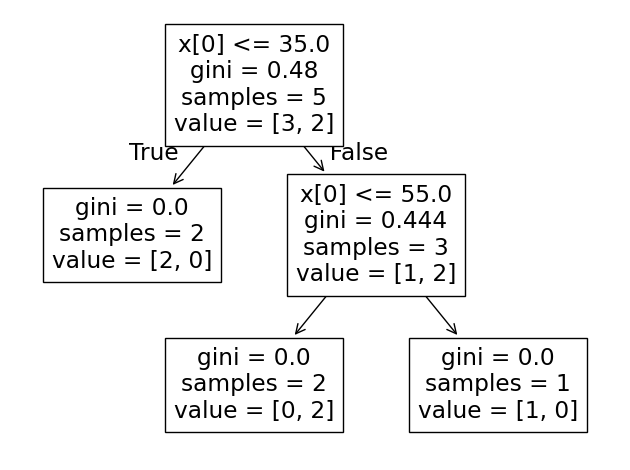

In [36]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plot_tree(dt)
plt.tight_layout()
plt.show()
#below 35 do not have hypertension
#above 35 do have hypertension
#below or above 55 have hypertension

Part 2: applying these ML models to our NHANES data

In [38]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [39]:
X_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_train.csv')
X_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_test.csv')
y_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_train.csv')
y_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_test.csv')

In [40]:
y_train =  y_train.squeeze()
y_test = y_test.squeeze()

In [41]:
#logistic regression
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

In [42]:
#pick one patient from the test dataset
patient = X_test.iloc[[243]]

In [44]:
patient
#scaling step is used to prevent the favoring of the higher absolute value

,age,bmi,height_cm,systolic_bp,gender_Male,race_ethnicity_Black,race_ethnicity_Mexican American,race_ethnicity_Other,race_ethnicity_Other Hispanic,race_ethnicity_White,education_College grad,education_Do not know,education_High school,education_Less than 9th,education_Some college
243,0.776425,1.479961,-0.391115,1.444984,False,False,False,False,False,True,False,False,True,False,False


In [46]:
#find out weather a patient has diabetes or not
y_test.iloc[[243]]

np.int64(1)

np.int64(1)

In [48]:
#using logistic regression model to see this patients was predicted is accurate
lr.predict(patient)[0]
#it shows that the prediction was accuratly wrong

np.int64(0)

In [49]:
#now predict the whole tested dataset
y_pred = lr.predict(X_test)

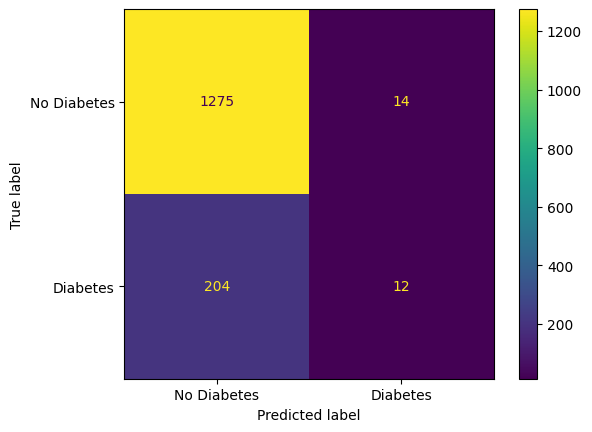

In [50]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,
                                        display_labels=['No Diabetes','Diabetes'])
plt.show()

predicted labels

In [53]:
#applying descision tree to our dataset
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [52]:
#testing on our one patient sample
dt.predict(patient)[0]

np.int64(0)

np.int64(0)

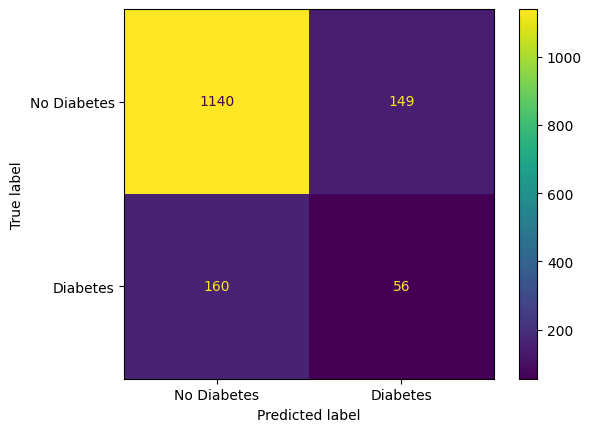

In [54]:
y_pred = dt.predict(X_test)
#apply desicion tree model to the test dataset
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,
                                        display_labels=['No Diabetes','Diabetes'])
plt.show()

random forest

In [55]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf.predict(patient)[0]
#x(patient)[0] we know has no diabetes


np.int64(1)

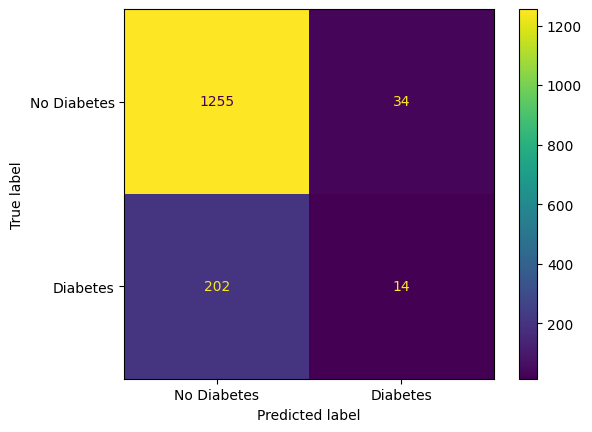

In [56]:
y_pred = rf.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,
                                        display_labels=['No Diabetes','Diabetes'])
plt.show()

XGBoost

In [57]:
#usually resaults in higher predictions
xgb = XGBClassifier(random_state=42)
xgb.fit(X_train,y_train)
xgb.predict(patient)[0]

np.int64(0)

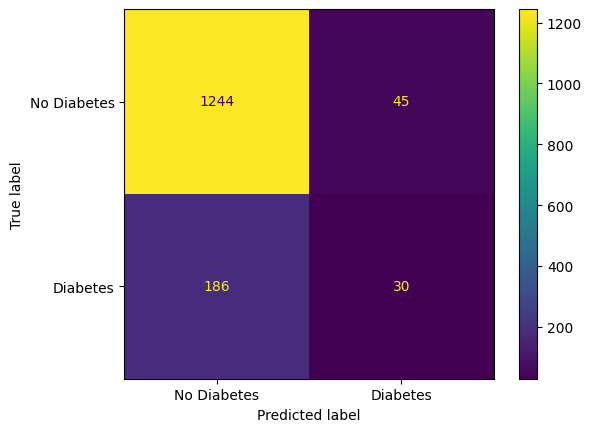

In [58]:
y_pred = xgb.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,
                                        display_labels=['No Diabetes','Diabetes'])
plt.show()

Neural network

In [59]:
nn = MLPClassifier(random_state=42, max_iter=500)
nn.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(max_iter=500, random_state=42)

In [60]:
nn.predict(patient)[0]

np.int64(0)

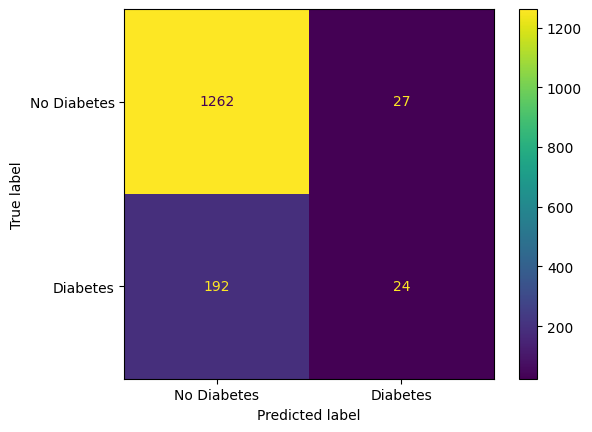

In [61]:
y_pred = nn.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,
                                        display_labels=['No Diabetes','Diabetes'])
plt.show()